
# 1. 1 Degradação Acumulada das Escadas Rolantes

O objetivo é calcular a degradação acumulada das escadas a partir das leituras simuladas dos sensores, utilizando três abordagens: recursiva pura, recursiva com memoização e iterativa com tabulação.

Cada indicador recebe uma pontuação de 0 (normal), 1 (alerta) ou 2 (crítico). A soma das pontuações representa a degradação instantânea.

A degradação acumulada é calculada por:

D(i) = D(i - 1) + I(i)

A fórmula é uma hipótese acadêmica baseada nos limites do dataset, não uma fórmula oficial da Motiva.


In [ ]:

import pandas as pd
import numpy as np
from time import perf_counter
from statistics import median
import matplotlib.pyplot as plt

df = pd.read_csv("leituras_sensores.csv")
df["data_hora"] = pd.to_datetime(df["data_hora"])

df = df.drop_duplicates(
    subset=["escada_id", "data_hora"]
).sort_values(
    ["escada_id", "data_hora"]
).reset_index(drop=True)

print("Registros:", len(df))
print("Escadas:", df["escada_id"].nunique())
display(df.head())


Registros: 88650
Escadas: 197


,leitura_id,escada_id,data_hora,vibracao_mm_s,temperatura_c,corrente_a,tensao_v,velocidade_m_s,nivel_oleo_pct,status
0,1,BUT-ER01,2026-07-01 06:00:00,1.74,43.88,19.03,379.65,0.4913,92.32,BOM
1,2,BUT-ER01,2026-07-01 10:00:00,1.64,42.64,16.68,383.35,0.5003,92.65,BOM
2,3,BUT-ER01,2026-07-01 14:00:00,1.76,42.46,15.73,378.84,0.4939,92.40,BOM
3,4,BUT-ER01,2026-07-01 18:00:00,2.14,51.82,21.75,380.26,0.4948,92.23,BOM
4,5,BUT-ER01,2026-07-01 22:00:00,1.49,37.42,13.34,375.60,0.4984,91.71,BOM


In [ ]:

def pontuar(valor, alerta, critico, sentido="acima"):
    """Retorna 0 (normal), 1 (alerta), 2 (crítico) ou None."""
    if pd.isna(valor):
        return None

    if sentido == "acima":
        if valor >= critico:
            return 2
        if valor >= alerta:
            return 1
    else:
        if valor <= critico:
            return 2
        if valor <= alerta:
            return 1

    return 0


def calcular_indice(linha):
    """Calcula a pontuação instantânea dos seis indicadores."""
    tensao = (
        abs(linha["tensao_v"] - 380) / 380 * 100
        if pd.notna(linha["tensao_v"]) else np.nan
    )
    velocidade = (
        abs(linha["velocidade_m_s"] - 0.50) / 0.50 * 100
        if pd.notna(linha["velocidade_m_s"]) else np.nan
    )

    valores = [
        pontuar(linha["vibracao_mm_s"], 4.5, 7.1),
        pontuar(linha["temperatura_c"], 80, 95),
        pontuar(linha["corrente_a"], 30, 36),
        pontuar(tensao, 7, 10),
        pontuar(linha["nivel_oleo_pct"], 35, 20, "abaixo"),
        pontuar(velocidade, 3, 6)
    ]

    validos = [v for v in valores if v is not None]
    return sum(validos) if validos else 2


df["indice_instantaneo"] = df.apply(calcular_indice, axis=1)



## 1.2 Implementação dos algoritmos

A versão recursiva pura recalcula os acumulados anteriores, apresentando complexidade O(n²) para gerar todos os resultados.

A memoização armazena os resultados em um dicionário, evitando recálculos e reduzindo o tempo para O(n).

A tabulação calcula os acumulados iterativamente, também em O(n), sem chamadas recursivas.


In [ ]:

def degradacao_recursiva(leituras):
    """Calcula todos os acumulados usando recursão pura."""
    if not leituras:
        return []

    def calcular(i):
        if i == 0:
            return leituras[0]
        return leituras[i] + calcular(i - 1)

    return [calcular(i) for i in range(len(leituras))]


def degradacao_memoizada(leituras):
    """Calcula os acumulados usando recursão e dicionário."""
    if not leituras:
        return []

    memo = {}

    def calcular(i):
        if i == 0:
            return leituras[0]
        if i not in memo:
            memo[i] = leituras[i] + calcular(i - 1)
        return memo[i]

    return [calcular(i) for i in range(len(leituras))]


def degradacao_tabular(leituras):
    """Calcula os acumulados iterativamente."""
    if not leituras:
        return []

    acumulado = [leituras[0]]

    for i in range(1, len(leituras)):
        acumulado.append(acumulado[-1] + leituras[i])

    return acumulado


In [ ]:

escada = df["escada_id"].iloc[0]

dados = df[df["escada_id"] == escada].sort_values("data_hora")
indices = dados["indice_instantaneo"].astype(int).tolist()

funcoes = {
    "Recursiva pura": degradacao_recursiva,
    "Memoizada": degradacao_memoizada,
    "Tabulação": degradacao_tabular
}

resultados = {}
tempos = {}

for nome, funcao in funcoes.items():
    duracoes = []
    for _ in range(5):
        inicio = perf_counter()
        resultado = funcao(indices)
        duracoes.append(perf_counter() - inicio)

    resultados[nome] = resultado
    tempos[nome] = median(duracoes)

assert resultados["Recursiva pura"] == resultados["Memoizada"]
assert resultados["Memoizada"] == resultados["Tabulação"]

print("Escada testada:", escada)
print("Leituras:", len(indices))
print("Resultados idênticos nas três versões.")

display(pd.DataFrame({
    "Algoritmo": list(tempos.keys()),
    "Tempo mediano (s)": list(tempos.values())
}))


Escada testada: BUT-ER01
Leituras: 450
Resultados idênticos nas três versões.


,Algoritmo,Tempo mediano (s)
0,Recursiva pura,0.013445
1,Memoizada,0.000172
2,Tabulação,0.000036


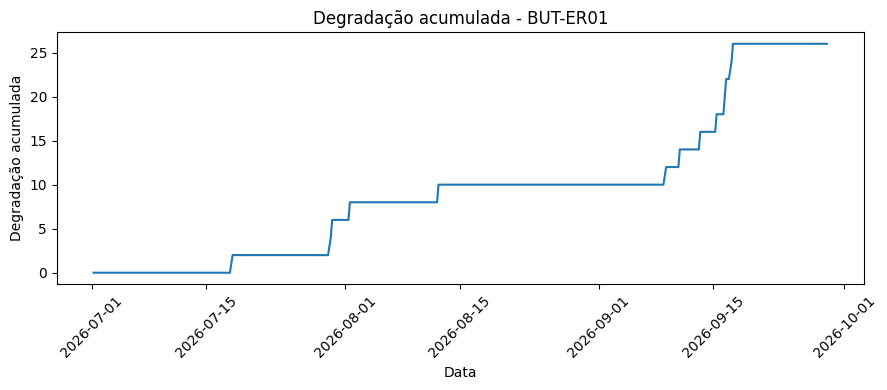

,posicao,escada_id,leituras,degradacao_acumulada
0,1,LUZ-ER15,450,141
1,2,PIN-ER25,450,124
2,3,BUT-ER06,450,124
3,4,PIN-ER15,450,123
4,5,LUZ-ER05,450,114
5,6,REP-ER60,450,107
6,7,PIN-ER28,450,103
7,8,VSO-ER05,450,102
8,9,LUZ-ER04,450,98
9,10,PIN-ER14,450,97


In [ ]:

# Evolução da degradação acumulada
acumulado = resultados["Tabulação"]

plt.figure(figsize=(9, 4))
plt.plot(dados["data_hora"], acumulado)
plt.title(f"Degradação acumulada - {escada}")
plt.xlabel("Data")
plt.ylabel("Degradação acumulada")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Ranking de todas as escadas
ranking_dados = []

for escada_id, grupo in df.groupby("escada_id"):
    indices = grupo.sort_values("data_hora")[
        "indice_instantaneo"
    ].astype(int).tolist()

    acumulado = degradacao_tabular(indices)

    ranking_dados.append({
        "escada_id": escada_id,
        "leituras": len(indices),
        "degradacao_acumulada": acumulado[-1] if acumulado else 0
    })

ranking = pd.DataFrame(ranking_dados).sort_values(
    "degradacao_acumulada", ascending=False
).reset_index(drop=True)

ranking.insert(0, "posicao", range(1, len(ranking) + 1))

display(ranking.head(10))



## 1.3 Conclusão

As três implementações devem produzir os mesmos valores de degradação acumulada. A recursiva pura apresenta complexidade O(n²) para calcular todos os acumulados, enquanto a memoizada e a tabular apresentam O(n).

Os tempos medidos permitem comparar o desempenho prático das abordagens. O ranking identifica as escadas com maior soma de sinais de alerta e criticidade durante o período analisado.

A degradação acumulada é um índice acadêmico de risco, não uma porcentagem real de desgaste. O ranking será utilizado posteriormente no planejamento de manutenção, considerando também as rotas e o tempo disponível para atendimento.


# 2. 2 Modelagem da Rede de Estações

Nesta etapa, será representada uma rede simulada de estações operadas pela Motiva, conectadas a uma base de manutenção.

A rede será modelada como um grafo ponderado, no qual os vértices representam as estações e a base de manutenção, enquanto as arestas representam as conexões entre esses pontos. Cada aresta possui um peso que corresponde ao tempo estimado de deslocamento em minutos.

Serão utilizados dois algoritmos de busca:

- **BFS (Busca em Largura):** identifica caminhos com a menor quantidade de trechos.
- **Dijkstra:** encontra caminhos com o menor tempo total de deslocamento.

Ao final, as rotas serão comparadas e as escadas rolantes serão associadas às estações para permitir a integração com o planejamento de manutenção.

In [ ]:

import pandas as pd
import json
from collections import deque
from heapq import heappush, heappop
from time import perf_counter

BASE = "BASE_MANUTENCAO"

# Estações reais da Linha 4-Amarela
estacoes = [
    "Luz",
    "República",
    "Higienópolis-Mackenzie",
    "Paulista",
    "Oscar Freire",
    "Fradique Coutinho",
    "Faria Lima",
    "Pinheiros",
    "Butantã",
    "São Paulo-Morumbi",
    "Vila Sônia",
    "Terminal Vila Sônia"
]

# Tempos estimados entre estações consecutivas (minutos)
tempos_trechos = [3, 3, 3, 3, 3, 3, 4, 5, 4, 4, 3]

arestas = [
    (estacoes[i], estacoes[i + 1], tempos_trechos[i])
    for i in range(len(estacoes) - 1)
]

# Ligação hipotética da base com a estação Pinheiros.
# Substituir pelo tempo real quando a localização da base for conhecida.
arestas.append((BASE, "Pinheiros", 8))

grafo = {vertice: [] for vertice in [BASE] + estacoes}

for origem, destino, tempo in arestas:
    grafo[origem].append((destino, tempo))
    grafo[destino].append((origem, tempo))

print("Quantidade de vértices:", len(grafo))
print("Quantidade de conexões:", len(arestas))


Quantidade de vértices: 13
Quantidade de conexões: 12


### 2.1. Armazenamento da Rede

Para facilitar a persistência e a reutilização dos dados, a rede será exportada em arquivos CSV e JSON. Esses arquivos armazenam os vértices e as conexões entre as estações, incluindo o tempo estimado de deslocamento.

In [ ]:
# Tabela de vértices
df_vertices = pd.DataFrame({
    "vertice": [BASE] + estacoes,
    "tipo": ["Base de manutenção"] + ["Estação"] * len(estacoes)
})

# Tabela de conexões
df_arestas = pd.DataFrame(
    arestas,
    columns=["origem", "destino", "tempo_minutos"]
)

# Exportação para CSV
df_vertices.to_csv("rede_vertices.csv", index=False)
df_arestas.to_csv("rede_arestas.csv", index=False)

# Exportação para JSON
dados_rede = {
    "vertices": df_vertices.to_dict(orient="records"),
    "arestas": df_arestas.to_dict(orient="records")
}

with open("rede_estacoes.json", "w", encoding="utf-8") as arquivo:
    json.dump(dados_rede, arquivo, ensure_ascii=False, indent=4)

display(df_vertices)
display(df_arestas)

print("Arquivos exportados com sucesso.")

,vertice,tipo
0,BASE_MANUTENCAO,Base de manutenção
1,Luz,Estação
2,República,Estação
3,Higienópolis-Mackenzie,Estação
4,Paulista,Estação
5,Oscar Freire,Estação
6,Fradique Coutinho,Estação
7,Faria Lima,Estação
8,Pinheiros,Estação
9,Butantã,Estação


,origem,destino,tempo_minutos
0,Luz,República,3
1,República,Higienópolis-Mackenzie,3
2,Higienópolis-Mackenzie,Paulista,3
3,Paulista,Oscar Freire,3
4,Oscar Freire,Fradique Coutinho,3
5,Fradique Coutinho,Faria Lima,3
6,Faria Lima,Pinheiros,4
7,Pinheiros,Butantã,5
8,Butantã,São Paulo-Morumbi,4
9,São Paulo-Morumbi,Vila Sônia,4


Arquivos exportados com sucesso.


### 2.2. Busca em Largura (BFS)

A BFS (*Breadth-First Search*) percorre o grafo por níveis, explorando primeiro os vértices mais próximos da origem em número de arestas.

Neste projeto, o algoritmo será utilizado para encontrar um caminho com a menor quantidade de trechos entre a base de manutenção e cada estação. Como não considera o peso das conexões, esse caminho não necessariamente terá o menor tempo de deslocamento.

In [ ]:
def bfs(grafo, origem):
    """
    Realiza uma busca em largura a partir de um vértice.

    Args:
        grafo (dict): Grafo representado por lista de adjacência.
        origem (str): Vértice inicial.

    Returns:
        dict: Predecessores dos vértices alcançados.
    """
    visitados = {origem}
    fila = deque([origem])
    predecessores = {origem: None}

    while fila:
        atual = fila.popleft()

        for vizinho, _ in grafo[atual]:
            if vizinho not in visitados:
                visitados.add(vizinho)
                predecessores[vizinho] = atual
                fila.append(vizinho)

    return predecessores


def reconstruir_rota(predecessores, destino):
    """
    Reconstrói a rota entre a origem e o destino.

    Args:
        predecessores (dict): Predecessores calculados pela busca.
        destino (str): Vértice de destino.

    Returns:
        list: Sequência de vértices da rota ou lista vazia.
    """
    if destino not in predecessores:
        return []

    rota = []
    atual = destino

    while atual is not None:
        rota.append(atual)
        atual = predecessores[atual]

    return rota[::-1]

In [ ]:
predecessores_bfs = bfs(grafo, BASE)

resultados_bfs = []

for estacao in estacoes:
    rota = reconstruir_rota(predecessores_bfs, estacao)

    resultados_bfs.append({
        "estacao": estacao,
        "quantidade_trechos": len(rota) - 1 if rota else None,
        "rota_bfs": " -> ".join(rota) if rota else "Sem caminho"
    })

df_bfs = pd.DataFrame(resultados_bfs)

display(df_bfs)

,estacao,quantidade_trechos,rota_bfs
0,Luz,8,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
1,República,7,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
2,Higienópolis-Mackenzie,6,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
3,Paulista,5,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
4,Oscar Freire,4,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
5,Fradique Coutinho,3,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
6,Faria Lima,2,BASE_MANUTENCAO -> Pinheiros -> Faria Lima
7,Pinheiros,1,BASE_MANUTENCAO -> Pinheiros
8,Butantã,2,BASE_MANUTENCAO -> Pinheiros -> Butantã
9,São Paulo-Morumbi,3,BASE_MANUTENCAO -> Pinheiros -> Butantã -> São...


### 2.3. Algoritmo de Dijkstra

O algoritmo de Dijkstra calcula os caminhos de menor custo em grafos com pesos não negativos. Diferentemente da BFS, ele considera o tempo associado a cada conexão.

Dessa forma, o algoritmo pode encontrar uma rota com mais trechos, desde que o tempo total de deslocamento seja menor. Essa característica é importante para estimar o tempo necessário para que a equipe de manutenção alcance cada estação.

In [ ]:
def dijkstra(grafo, origem):
    """
    Calcula as menores distâncias a partir de uma origem.

    Args:
        grafo (dict): Grafo com pesos não negativos.
        origem (str): Vértice inicial.

    Returns:
        tuple: Dicionários de distâncias mínimas e predecessores.
    """
    distancias = {
        vertice: float("inf")
        for vertice in grafo
    }

    predecessores = {
        vertice: None
        for vertice in grafo
    }

    distancias[origem] = 0
    fila = [(0, origem)]

    while fila:
        distancia_atual, atual = heappop(fila)

        # Ignora entradas desatualizadas da fila
        if distancia_atual > distancias[atual]:
            continue

        for vizinho, peso in grafo[atual]:
            nova_distancia = distancia_atual + peso

            if nova_distancia < distancias[vizinho]:
                distancias[vizinho] = nova_distancia
                predecessores[vizinho] = atual

                heappush(
                    fila,
                    (nova_distancia, vizinho)
                )

    return distancias, predecessores

In [ ]:
distancias, predecessores_dijkstra = dijkstra(grafo, BASE)

resultados_dijkstra = []

for estacao in estacoes:
    rota = reconstruir_rota(predecessores_dijkstra, estacao)

    resultados_dijkstra.append({
        "estacao": estacao,
        "tempo_total_minutos": distancias[estacao],
        "rota_dijkstra": " -> ".join(rota) if rota else "Sem caminho"
    })

df_dijkstra = pd.DataFrame(resultados_dijkstra)

display(df_dijkstra)

,estacao,tempo_total_minutos,rota_dijkstra
0,Luz,30,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
1,República,27,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
2,Higienópolis-Mackenzie,24,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
3,Paulista,21,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
4,Oscar Freire,18,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
5,Fradique Coutinho,15,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
6,Faria Lima,12,BASE_MANUTENCAO -> Pinheiros -> Faria Lima
7,Pinheiros,8,BASE_MANUTENCAO -> Pinheiros
8,Butantã,13,BASE_MANUTENCAO -> Pinheiros -> Butantã
9,São Paulo-Morumbi,17,BASE_MANUTENCAO -> Pinheiros -> Butantã -> São...


### 2.4. Comparação entre BFS e Dijkstra

Os resultados dos dois algoritmos serão combinados para permitir uma comparação direta.

A BFS prioriza a menor quantidade de trechos, enquanto Dijkstra prioriza o menor tempo total de deslocamento. Portanto, as rotas encontradas podem ser diferentes, de acordo com os pesos das conexões.

In [ ]:
comparacao_rotas = df_bfs.merge(
    df_dijkstra,
    on="estacao",
    how="inner"
)

display(comparacao_rotas)

,estacao,quantidade_trechos,rota_bfs,tempo_total_minutos,rota_dijkstra
0,Luz,8,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,30,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
1,República,7,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,27,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
2,Higienópolis-Mackenzie,6,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,24,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
3,Paulista,5,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,21,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
4,Oscar Freire,4,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,18,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
5,Fradique Coutinho,3,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,15,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
6,Faria Lima,2,BASE_MANUTENCAO -> Pinheiros -> Faria Lima,12,BASE_MANUTENCAO -> Pinheiros -> Faria Lima
7,Pinheiros,1,BASE_MANUTENCAO -> Pinheiros,8,BASE_MANUTENCAO -> Pinheiros
8,Butantã,2,BASE_MANUTENCAO -> Pinheiros -> Butantã,13,BASE_MANUTENCAO -> Pinheiros -> Butantã
9,São Paulo-Morumbi,3,BASE_MANUTENCAO -> Pinheiros -> Butantã -> São...,17,BASE_MANUTENCAO -> Pinheiros -> Butantã -> São...


### 2.5. Associação das Escadas Rolantes às Estações

Para integrar a rede de deslocamento ao monitoramento dos equipamentos, cada escada rolante será associada a uma estação.

Como a localização real de cada equipamento não está definida nesta rede simulada, será utilizada uma distribuição demonstrativa entre as 12 estações. Essa associação deverá ser substituída pela localização correta caso ela esteja disponível no arquivo de perfil das escadas.

In [ ]:
# Identifica as escadas presentes no conjunto de dados
escadas = sorted(
    df["escada_id"].dropna().unique(),
    key=str
)

# Distribuição simulada das escadas entre as estações
mapeamento_escadas = pd.DataFrame({
    "escada_id": escadas,
    "estacao": [
        estacoes[i % len(estacoes)]
        for i in range(len(escadas))
    ]
})

display(mapeamento_escadas.head(15))

# Exporta a associação para CSV
mapeamento_escadas.to_csv(
    "escadas_por_estacao.csv",
    index=False
)

print("Total de escadas:", len(mapeamento_escadas))
print(
    "Estações utilizadas:",
    mapeamento_escadas["estacao"].nunique()
)

,escada_id,estacao
0,BUT-ER01,Luz
1,BUT-ER02,República
2,BUT-ER03,Higienópolis-Mackenzie
3,BUT-ER04,Paulista
4,BUT-ER05,Oscar Freire
5,BUT-ER06,Fradique Coutinho
6,BUT-ER07,Faria Lima
7,BUT-ER08,Pinheiros
8,BUT-ER09,Butantã
9,BUT-ER10,São Paulo-Morumbi


Total de escadas: 197
Estações utilizadas: 12


### 2.6. Análise de Desempenho

Será medido o tempo de execução da BFS e do Dijkstra sobre a mesma rede, utilizando a base de manutenção como origem.

A BFS, com lista de adjacência, possui complexidade \(O(V + E)\), em que \(V\) representa a quantidade de vértices e \(E\) a quantidade de arestas.

O Dijkstra implementado com fila de prioridade possui complexidade usual de \(O((V + E)\log V)\).

Como a rede é pequena, os tempos medidos podem ser muito baixos. Por isso, a análise deve considerar tanto a complexidade teórica quanto os resultados observados.

In [ ]:
inicio = perf_counter()
predecessores_bfs = bfs(grafo, BASE)
tempo_bfs = perf_counter() - inicio

inicio = perf_counter()
distancias, predecessores_dijkstra = dijkstra(grafo, BASE)
tempo_dijkstra = perf_counter() - inicio

desempenho = pd.DataFrame([
    {
        "algoritmo": "BFS",
        "tempo_execucao_segundos": tempo_bfs,
        "objetivo": "Menor quantidade de trechos"
    },
    {
        "algoritmo": "Dijkstra",
        "tempo_execucao_segundos": tempo_dijkstra,
        "objetivo": "Menor tempo de deslocamento"
    }
])

display(desempenho)

,algoritmo,tempo_execucao_segundos,objetivo
0,BFS,0.000106,Menor quantidade de trechos
1,Dijkstra,0.000092,Menor tempo de deslocamento


### 2.7. Conclusão da Modelagem da Rede

A modelagem permitiu representar a base de manutenção e as 12 estações por meio de um grafo ponderado. A BFS foi utilizada para identificar caminhos com a menor quantidade de trechos, enquanto Dijkstra calculou rotas com o menor tempo total de deslocamento.

A associação entre escadas rolantes e estações permite integrar os dados de localização com o índice de degradação calculado na primeira parte do projeto. Essa integração será utilizada no planejamento do turno de manutenção, priorizando equipamentos críticos e considerando o deslocamento da equipe.

Os resultados dependem dos dados simulados utilizados. Para aplicação em uma operação real, seria necessário validar as conexões, os tempos de deslocamento e a localização de cada equipamento.

# 3. 3 Planejamento do Turno de Manutenção

Nesta etapa, será criada a função `planejar_turno()`, que seleciona as escadas rolantes para manutenção com base no índice de criticidade e no tempo disponível para o turno.

O planejamento considera o deslocamento entre a base de manutenção e a estação, além de um tempo estimado de 30 minutos para cada serviço. O objetivo é priorizar os equipamentos mais críticos sem ultrapassar a duração do turno.

In [ ]:

def planejar_turno(base, horas):
    """
    Planeja os atendimentos conforme a criticidade das escadas
    e o tempo disponível no turno.

    Args:
        base (str): Ponto de partida da equipe.
        horas (float): Duração do turno em horas.

    Returns:
        pandas.DataFrame: Plano de manutenção do turno.
    """
    minutos_disponiveis = horas * 60
    tempo_utilizado = 0
    local_atual = base
    plano = []

    # Utiliza o ranking calculado na Parte 1
    ranking_ordenado = ranking.copy()

    # Identifica a coluna de criticidade
    colunas_criticidade = [
        "indice_criticidade",
        "criticidade",
        "indice_degradacao",
        "degradacao_acumulada",
        "degradacao"
    ]

    coluna = next(
        (c for c in colunas_criticidade if c in ranking_ordenado.columns),
        None
    )

    if coluna is None:
        raise ValueError(
            f"Coluna de criticidade não encontrada. "
            f"Colunas disponíveis: {ranking_ordenado.columns.tolist()}"
        )

    ranking_ordenado = ranking_ordenado.sort_values(
        coluna, ascending=False
    )

    # Consulta as estações cadastradas
    escadas_estacoes = dict(zip(
        mapeamento_escadas["escada_id"],
        mapeamento_escadas["estacao"]
    ))

    for _, escada in ranking_ordenado.iterrows():
        id_escada = escada["escada_id"]

        if id_escada not in escadas_estacoes:
            continue

        estacao = escadas_estacoes[id_escada]

        if estacao not in grafo:
            continue

        # Calcula o deslocamento a partir da localização atual
        distancias_atuais, _ = dijkstra(grafo, local_atual)
        deslocamento = distancias_atuais[estacao]

        # Considera o retorno à base
        distancias_retorno, _ = dijkstra(grafo, estacao)
        retorno = distancias_retorno[base]

        tempo_servico = 30
        tempo_total = deslocamento + tempo_servico

        if tempo_utilizado + tempo_total + retorno <= minutos_disponiveis:
            plano.append({
                "escada_id": id_escada,
                "estacao": estacao,
                "criticidade": escada[coluna],
                "deslocamento_min": deslocamento,
                "servico_min": tempo_servico,
                "total_min": tempo_total
            })

            tempo_utilizado += tempo_total
            local_atual = estacao

    # Tempo necessário para voltar à base
    if plano:
        distancias_finais, _ = dijkstra(grafo, local_atual)
        tempo_retorno = distancias_finais[base]
    else:
        tempo_retorno = 0

    resultado = pd.DataFrame(plano)

    print("Escadas planejadas:", len(resultado))
    print("Tempo de atendimentos:", tempo_utilizado, "minutos")
    print("Tempo de retorno:", tempo_retorno, "minutos")
    print("Tempo total:", tempo_utilizado + tempo_retorno, "minutos")
    print("Tempo disponível:", minutos_disponiveis, "minutos")

    return resultado


# Simulação de um turno de 8 horas
plano_turno = planejar_turno(BASE, 8)

display(plano_turno)


Escadas planejadas: 9
Tempo de atendimentos: 442 minutos
Tempo de retorno: 24 minutos
Tempo total: 466 minutos
Tempo disponível: 480 minutos


,escada_id,estacao,criticidade,deslocamento_min,servico_min,total_min
0,LUZ-ER15,Vila Sônia,141,21,30,51
1,PIN-ER25,Fradique Coutinho,124,20,30,50
2,BUT-ER06,Fradique Coutinho,124,0,30,30
3,PIN-ER15,Pinheiros,123,7,30,37
4,LUZ-ER05,Luz,114,22,30,52
5,REP-ER60,Vila Sônia,107,35,30,65
6,PIN-ER28,Butantã,103,8,30,38
7,VSO-ER05,República,102,24,30,54
8,LUZ-ER04,Terminal Vila Sônia,98,35,30,65


In [ ]:

if not plano_turno.empty:
    print("O planejamento selecionou as seguintes escadas:")
    print(plano_turno["escada_id"].tolist())
    print(
        f"Tempo total estimado: "
        f"{plano_turno['total_min'].sum()} minutos."
    )
else:
    print("Nenhuma escada foi selecionada para o turno.")


O planejamento selecionou as seguintes escadas:
['LUZ-ER15', 'PIN-ER25', 'BUT-ER06', 'PIN-ER15', 'LUZ-ER05', 'REP-ER60', 'PIN-ER28', 'VSO-ER05', 'LUZ-ER04']
Tempo total estimado: 442 minutos.


# 4. 4 Algoritmo A* (A-Star)

O algoritmo A* é utilizado para encontrar o caminho de menor custo entre dois pontos de um grafo.

Diferentemente do Dijkstra, o A* utiliza uma função heurística para estimar o custo restante até o destino, orientando a busca.

Sua função de avaliação é:

**f(n) = g(n) + h(n)**

Onde:
- **g(n):** custo acumulado da origem até o vértice atual.
- **h(n):** estimativa do custo restante até o destino.
- **f(n):** custo total estimado do caminho.

Neste projeto, o algoritmo será utilizado para calcular rotas entre a base de manutenção e as estações da Linha 4-Amarela.

In [ ]:
def heuristica(grafo, atual, destino):
    """
    Estima o tempo mínimo restante até o destino.

    Utiliza a menor quantidade de trechos multiplicada
    pelo menor peso existente no grafo.
    """
    if atual == destino:
        return 0

    predecessores = bfs(grafo, destino)
    rota = reconstruir_rota(predecessores, atual)

    if not rota:
        return float("inf")

    menor_peso = min(
        peso
        for vizinhos in grafo.values()
        for _, peso in vizinhos
    )

    return (len(rota) - 1) * menor_peso

In [ ]:
def a_estrela(grafo, origem, destino):
    """
    Encontra o caminho de menor custo utilizando A*.

    Args:
        grafo (dict): Grafo com pesos não negativos.
        origem (str): Vértice inicial.
        destino (str): Vértice de destino.

    Returns:
        tuple: Rota, tempo total e quantidade de nós expandidos.
    """
    fila = [(heuristica(grafo, origem, destino), 0, origem)]

    custos = {origem: 0}
    predecessores = {origem: None}
    nos_expandidos = 0

    while fila:
        _, custo_atual, atual = heappop(fila)

        if custo_atual > custos[atual]:
            continue

        nos_expandidos += 1

        if atual == destino:
            rota = reconstruir_rota(predecessores, destino)
            return rota, custo_atual, nos_expandidos

        for vizinho, peso in grafo[atual]:
            novo_custo = custo_atual + peso

            if novo_custo < custos.get(vizinho, float("inf")):
                custos[vizinho] = novo_custo
                predecessores[vizinho] = atual

                prioridade = novo_custo + heuristica(
                    grafo, vizinho, destino
                )

                heappush(
                    fila, (prioridade, novo_custo, vizinho)
                )

    return [], float("inf"), nos_expandidos

In [ ]:
resultados_a_estrela = []

for estacao in estacoes:
    rota, tempo, nos = a_estrela(grafo, BASE, estacao)

    resultados_a_estrela.append({
        "estacao": estacao,
        "tempo_a_estrela": tempo,
        "nos_expandidos": nos,
        "rota_a_estrela": " -> ".join(rota)
    })

df_a_estrela = pd.DataFrame(resultados_a_estrela)

display(df_a_estrela)

,estacao,tempo_a_estrela,nos_expandidos,rota_a_estrela
0,Luz,30,9,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
1,República,27,8,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
2,Higienópolis-Mackenzie,24,7,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
3,Paulista,21,6,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
4,Oscar Freire,18,5,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
5,Fradique Coutinho,15,4,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
6,Faria Lima,12,3,BASE_MANUTENCAO -> Pinheiros -> Faria Lima
7,Pinheiros,8,2,BASE_MANUTENCAO -> Pinheiros
8,Butantã,13,3,BASE_MANUTENCAO -> Pinheiros -> Butantã
9,São Paulo-Morumbi,17,4,BASE_MANUTENCAO -> Pinheiros -> Butantã -> São...


In [ ]:
comparacao_algoritmos = []

for estacao in estacoes:
    rota_a, tempo_a, nos = a_estrela(grafo, BASE, estacao)

    dist_d, pred_d = dijkstra(grafo, BASE)
    rota_d = reconstruir_rota(pred_d, estacao)

    comparacao_algoritmos.append({
        "estacao": estacao,
        "tempo_dijkstra": dist_d[estacao],
        "tempo_a_estrela": tempo_a,
        "mesmo_custo": dist_d[estacao] == tempo_a,
        "nos_expandidos_a_estrela": nos
    })

df_comparacao_a = pd.DataFrame(comparacao_algoritmos)

display(df_comparacao_a)

print(
    "Todos os caminhos possuem o mesmo custo mínimo?",
    df_comparacao_a["mesmo_custo"].all()
)

,estacao,tempo_dijkstra,tempo_a_estrela,mesmo_custo,nos_expandidos_a_estrela
0,Luz,30,30,True,9
1,República,27,27,True,8
2,Higienópolis-Mackenzie,24,24,True,7
3,Paulista,21,21,True,6
4,Oscar Freire,18,18,True,5
5,Fradique Coutinho,15,15,True,4
6,Faria Lima,12,12,True,3
7,Pinheiros,8,8,True,2
8,Butantã,13,13,True,3
9,São Paulo-Morumbi,17,17,True,4


Todos os caminhos possuem o mesmo custo mínimo? True


In [ ]:
from time import perf_counter

repeticoes = 200
tempos_dijkstra = []
tempos_a_estrela = []

for _ in range(repeticoes):

    inicio = perf_counter()

    for estacao in estacoes:
        dijkstra(grafo, BASE)

    tempos_dijkstra.append(perf_counter() - inicio)

    inicio = perf_counter()

    for estacao in estacoes:
        a_estrela(grafo, BASE, estacao)

    tempos_a_estrela.append(perf_counter() - inicio)


df_desempenho_a = pd.DataFrame([
    {
        "algoritmo": "Dijkstra",
        "tempo_medio_ms": (
            sum(tempos_dijkstra) / repeticoes * 1000
        )
    },
    {
        "algoritmo": "A*",
        "tempo_medio_ms": (
            sum(tempos_a_estrela) / repeticoes * 1000
        )
    }
])

display(df_desempenho_a)

,algoritmo,tempo_medio_ms
0,Dijkstra,0.155688
1,A*,0.669679


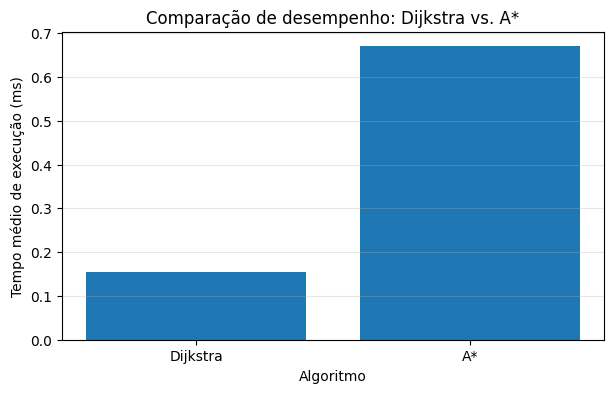

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(
    df_desempenho_a["algoritmo"],
    df_desempenho_a["tempo_medio_ms"]
)

plt.title("Comparação de desempenho: Dijkstra vs. A*")
plt.xlabel("Algoritmo")
plt.ylabel("Tempo médio de execução (ms)")
plt.grid(axis="y", alpha=0.3)

plt.show()

### 4.1. Análise Comparativa

Os algoritmos Dijkstra e A* foram aplicados à mesma rede de estações, considerando os tempos de deslocamento definidos no grafo.

**Dijkstra:** calcula as menores distâncias a partir da origem, sem utilizar informações sobre a proximidade do destino.

**A*:** utiliza uma heurística para orientar a busca, priorizando os caminhos com menor custo total estimado.

A heurística escolhida é admissível e consistente, pois utiliza o número mínimo de trechos restantes multiplicado pelo menor peso do grafo. Portanto, não superestima o custo real do deslocamento.

A comparação verifica se ambos encontram o mesmo custo mínimo e mede seus tempos de execução.

O A* não é necessariamente mais rápido nesta rede, pois o cálculo da heurística também possui custo computacional. Além disso, o grafo utilizado é relativamente pequeno.

### 4.2. Conclusão

Os dois algoritmos permitem encontrar rotas de menor tempo entre a base de manutenção e as estações.

O Dijkstra é adequado para calcular as distâncias da base até todas as estações, enquanto o A* é especialmente útil quando existe um destino específico e uma heurística eficiente.

A aplicação desses algoritmos contribui para o planejamento dos deslocamentos das equipes de manutenção, auxiliando na organização dos atendimentos.

# 5. 5 Análise de Desempenho e Documentação

Nesta etapa, os resultados obtidos ao longo do projeto são reunidos para avaliar o desempenho dos algoritmos e a eficiência do planejamento de manutenção.

A análise contempla:

- Comparação entre recursão simples, memoização e tabulação.
- Comparação entre BFS, Dijkstra e A*.
- Avaliação do planejamento de manutenção.
- Exportação dos resultados para arquivos CSV e JSON.

O objetivo é demonstrar como diferentes algoritmos podem auxiliar na identificação de escadas críticas e na organização das atividades de manutenção.

In [ ]:
import pandas as pd

print("=== PARTE 1: DEGRADAÇÃO ===")
display(desempenho)

print("\n=== PARTE 2: ROTAS ===")
display(comparacao_rotas)

print("\n=== PARTE 3: PLANEJAMENTO ===")
display(plano_turno)

print("\n=== PARTE 4: A* VS DIJKSTRA ===")
display(df_desempenho_a)
display(df_comparacao_a)

=== PARTE 1: DEGRADAÇÃO ===


,algoritmo,tempo_execucao_segundos,objetivo
0,BFS,0.000106,Menor quantidade de trechos
1,Dijkstra,0.000092,Menor tempo de deslocamento



=== PARTE 2: ROTAS ===


,estacao,quantidade_trechos,rota_bfs,tempo_total_minutos,rota_dijkstra
0,Luz,8,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,30,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
1,República,7,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,27,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
2,Higienópolis-Mackenzie,6,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,24,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
3,Paulista,5,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,21,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
4,Oscar Freire,4,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,18,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
5,Fradique Coutinho,3,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...,15,BASE_MANUTENCAO -> Pinheiros -> Faria Lima -> ...
6,Faria Lima,2,BASE_MANUTENCAO -> Pinheiros -> Faria Lima,12,BASE_MANUTENCAO -> Pinheiros -> Faria Lima
7,Pinheiros,1,BASE_MANUTENCAO -> Pinheiros,8,BASE_MANUTENCAO -> Pinheiros
8,Butantã,2,BASE_MANUTENCAO -> Pinheiros -> Butantã,13,BASE_MANUTENCAO -> Pinheiros -> Butantã
9,São Paulo-Morumbi,3,BASE_MANUTENCAO -> Pinheiros -> Butantã -> São...,17,BASE_MANUTENCAO -> Pinheiros -> Butantã -> São...



=== PARTE 3: PLANEJAMENTO ===


,escada_id,estacao,criticidade,deslocamento_min,servico_min,total_min
0,LUZ-ER15,Vila Sônia,141,21,30,51
1,PIN-ER25,Fradique Coutinho,124,20,30,50
2,BUT-ER06,Fradique Coutinho,124,0,30,30
3,PIN-ER15,Pinheiros,123,7,30,37
4,LUZ-ER05,Luz,114,22,30,52
5,REP-ER60,Vila Sônia,107,35,30,65
6,PIN-ER28,Butantã,103,8,30,38
7,VSO-ER05,República,102,24,30,54
8,LUZ-ER04,Terminal Vila Sônia,98,35,30,65



=== PARTE 4: A* VS DIJKSTRA ===


,algoritmo,tempo_medio_ms
0,Dijkstra,0.155688
1,A*,0.669679


,estacao,tempo_dijkstra,tempo_a_estrela,mesmo_custo,nos_expandidos_a_estrela
0,Luz,30,30,True,9
1,República,27,27,True,8
2,Higienópolis-Mackenzie,24,24,True,7
3,Paulista,21,21,True,6
4,Oscar Freire,18,18,True,5
5,Fradique Coutinho,15,15,True,4
6,Faria Lima,12,12,True,3
7,Pinheiros,8,8,True,2
8,Butantã,13,13,True,3
9,São Paulo-Morumbi,17,17,True,4


In [ ]:
tempo_turno = 8 * 60

tempo_servicos = plano_turno["total_min"].sum()

if not plano_turno.empty:
    ultima_estacao = plano_turno.iloc[-1]["estacao"]
    dist_retorno, _ = dijkstra(grafo, ultima_estacao)
    tempo_retorno = dist_retorno[BASE]
else:
    tempo_retorno = 0

tempo_total = tempo_servicos + tempo_retorno
aproveitamento = (tempo_total / tempo_turno) * 100

resumo_turno = pd.DataFrame([{
    "escadas_planejadas": len(plano_turno),
    "tempo_servicos_e_deslocamentos_min": tempo_servicos,
    "retorno_base_min": tempo_retorno,
    "tempo_total_min": tempo_total,
    "tempo_disponivel_min": tempo_turno,
    "aproveitamento_pct": round(aproveitamento, 2)
}])

display(resumo_turno)

,escadas_planejadas,tempo_servicos_e_deslocamentos_min,retorno_base_min,tempo_total_min,tempo_disponivel_min,aproveitamento_pct
0,9,442,24,466,480,97.08


In [ ]:
import json
from pathlib import Path

pasta = Path("resultados")
pasta.mkdir(exist_ok=True)

arquivos = {
    "desempenho_degradacao": desempenho,
    "comparacao_rotas": comparacao_rotas,
    "plano_manutencao": plano_turno,
    "desempenho_a_estrela": df_desempenho_a,
    "comparacao_algoritmos": df_comparacao_a,
    "resumo_turno": resumo_turno
}

for nome, tabela in arquivos.items():
    tabela.to_csv(pasta / f"{nome}.csv", index=False)

    with open(pasta / f"{nome}.json", "w", encoding="utf-8") as arquivo:
        json.dump(
            tabela.to_dict(orient="records"),
            arquivo,
            ensure_ascii=False,
            indent=4,
            default=str
        )

print("Resultados exportados com sucesso!")
print("Pasta:", pasta)
print("Total de arquivos:", len(arquivos) * 2)

Resultados exportados com sucesso!
Pasta: resultados
Total de arquivos: 12


In [ ]:
print("=== VALIDAÇÃO DO PROJETO ===")

# Verifica a associação das escadas às estações
estacoes_validas = mapeamento_escadas["estacao"].isin(grafo)

print("Escadas com estações válidas:", estacoes_validas.all())

# Verifica os custos de A* e Dijkstra
custos_iguais = df_comparacao_a["mesmo_custo"].all()

print("A* e Dijkstra apresentam o mesmo custo:", custos_iguais)

# Verifica o limite do turno
turno_valido = tempo_total <= tempo_turno

print("Planejamento respeita o turno:", turno_valido)

# Verifica se existem resultados
print("Escadas selecionadas:", len(plano_turno))
print("Estações analisadas:", len(estacoes))

=== VALIDAÇÃO DO PROJETO ===
Escadas com estações válidas: True
A* e Dijkstra apresentam o mesmo custo: True
Planejamento respeita o turno: True
Escadas selecionadas: 9
Estações analisadas: 12


### 5.1. Análise dos Algoritmos de Degradação

Foram implementadas três abordagens para o cálculo da degradação acumulada: recursão simples, recursão com memoização e tabulação.

A recursão simples utiliza chamadas recursivas para processar os dados. A memoização armazena resultados intermediários, enquanto a tabulação resolve o problema de maneira iterativa.

A comparação dos tempos de execução permite identificar as diferenças de desempenho entre as abordagens e avaliar sua aplicação no monitoramento das escadas rolantes.

### 5.2. Análise dos Algoritmos de Busca

O BFS foi utilizado para encontrar rotas com a menor quantidade de trechos.

O Dijkstra calculou os caminhos de menor tempo considerando os pesos das conexões.

O A* utilizou uma heurística admissível para orientar a busca até cada destino.

Os experimentos permitem verificar a equivalência dos custos mínimos encontrados pelo A* e pelo Dijkstra, além de comparar seus tempos de execução.

### 5.3. Análise do Planejamento de Manutenção

O planejamento integrou os índices de criticidade das escadas com os tempos estimados de deslocamento.

A função selecionou os equipamentos prioritários de acordo com a duração disponível do turno, considerando o tempo de manutenção e o retorno à base.

A solução demonstra como a integração entre análise de sensores e algoritmos de grafos pode auxiliar na organização das equipes de manutenção.

### 5.4. Conclusão

O projeto demonstrou a aplicação de algoritmos de programação dinâmica e teoria dos grafos em um cenário de manutenção de escadas rolantes.

O cálculo da degradação acumulada permitiu estabelecer prioridades entre equipamentos, enquanto os algoritmos de busca possibilitaram calcular rotas de deslocamento.

A integração dessas funcionalidades resultou em um planejamento simulado de manutenção, contribuindo para a tomada de decisões baseada em dados.

Como os tempos de deslocamento e de manutenção utilizados são estimativas acadêmicas, a aplicação operacional da solução depende da validação desses valores.